In [ ]:
#=============================================================================================================
                                    # NOTICE

#  1.  variables['topics'][i]['size'] HAS BEEN CHANGED TO variables['topics'][i]['total_comments']
#       #CHANGE IT IN THIS NOTEBOOK RIGHT NOW 

#  2.  SPAM COMMENTS ARE NOW INCLUDED IN THE COUNT

#  3. in case of MULTIPLE CATEGORIES, i changed the code in process_data.py to only choose one of them

#=============================================================================================================

In [91]:
from prepare_dashboard import gather_data
import plotly.graph_objects as go

In [267]:
variables = gather_data("https://www.youtube.com/watch?v=MmNFJ4CGvyw&t=1141s")

2026-07-26 04:14:09,883 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-07-26 04:14:10,194 - BERTopic - Dimensionality - Completed ✓
2026-07-26 04:14:10,197 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-07-26 04:14:10,256 - BERTopic - Cluster - Completed ✓
2026-07-26 04:14:10,289 - BERTopic - Representation - Fine-tuning topics using representation models.
100%|██████████| 5/5 [00:14<00:00,  2.96s/it]
2026-07-26 04:14:25,229 - BERTopic - Representation - Completed ✓


response :  {
  "category": "Love",
  "summary": "The commenters express deep appreciation and admiration for the video content related to 0_India-US Tariffs, highlighting its authenticity, educational value, and relevance to global issues. They praise the detailed connection of historical origins of tariffs with current trade dynamics, benefiting viewers preparing for exams like Civil Services. There is also commendation for the handling of tariffs by the Indian government in protecting farmers, garnering respect from the commenters.",
  "creator_takeaway": "The creator should continue producing insightful and comprehensive content that bridges historical contexts with contemporary issues, as it significantly resonates with educational and professional audiences seeking deep knowledge on global topics like trade tariffs. The positive feedback indicates a strong demand for such detailed and authoritative information."
}
response :  {"category": "Hate",
  "summary": "The comments expres

In [250]:
import pickle
with open("variables_state.pkl","wb") as fb:
    pickle.dump(variables,fb)

In [ ]:
with open("variables_state.pkl","rb") as fb:
    variables = pickle.load(fb)

In [268]:
# Count of topics by category
love_topics = [t for t in variables['topics'] if 'love' in t['category'].lower()]
hate_topics = [t for t in variables['topics'] if 'hate' in t['category'].lower()]
request_topics = [t for t in variables['topics'] if 'request' in t['category'].lower()]
suggestion_topics = [t for t in variables['topics'] if 'suggestion' in t['category'].lower()]

total_topics = len(variables['topics'])


In [269]:

# Total comments (size) for each category
n_love_comments = sum(t['size'] for t in love_topics)
n_hate_comments = sum(t['size'] for t in hate_topics)
n_request_comments = sum(t['size'] for t in request_topics)
n_suggestion_comments = sum(t['size'] for t in suggestion_topics)

n_total_comments = sum(t['size'] for t in variables['topics'])

In [270]:
import plotly.graph_objects as go

percentage = (n_love_comments / n_total_comments) * 100

fig = go.Figure()

fig.add_trace(
    go.Indicator(
        mode="number",
        value=percentage,
        number={
            "suffix": " %",
            "font": {"size": 60}     # Percentage size
        },
        title={
            "text": (
                "<span style='font-size:34px'><b>Love 💕</b></span><br><br>"
                f"<span style='font-size:18px ; text-align:left'>{len(love_topics)} topics</span>  "
                f"<span style='font-size:18px'>{n_love_comments} comments</span>"
            )
        }
    )
)

fig.update_layout(
    height=250,
    width=400,
    margin=dict(l=20, r=20, t=40, b=20),
    paper_bgcolor="white",
)

fig.show()


In [271]:
# ---------------- HATE ----------------
percentage = (n_hate_comments / n_total_comments) * 100

fig = go.Figure()

fig.add_trace(
    go.Indicator(
        mode="number",
        value=percentage,
        number={
            "suffix": " %",
            "font": {"size": 60}
        },
        title={
            "text": (
                "<span style='font-size:34px'><b>Hate 😡</b></span><br><br>"
                f"<span style='font-size:18px'>{len(hate_topics)} topics</span>&nbsp;&nbsp;&nbsp;"
                f"<span style='font-size:18px'>{n_hate_comments} comments</span>"
            )
        }
    )
)

fig.update_layout(
    height=250,
    width=400,
    margin=dict(l=20, r=20, t=40, b=20),
    paper_bgcolor="white",
)

fig.show()

In [272]:
# ---------------- REQUESTS ----------------
percentage = (n_request_comments / n_total_comments) * 100

fig = go.Figure()

fig.add_trace(
    go.Indicator(
        mode="number",
        value=percentage,
        number={
            "suffix": " %",
            "font": {"size": 60}
        },
        title={
            "text": (
                "<span style='font-size:34px'><b>Requests 🙋</b></span><br><br>"
                f"<span style='font-size:18px'>{len(request_topics)} topics</span>&nbsp;&nbsp;&nbsp;"
                f"<span style='font-size:18px'>{n_request_comments} comments</span>"
            )
        }
    )
)

fig.update_layout(
    height=250,
    width=400,
    margin=dict(l=20, r=20, t=40, b=20),
    paper_bgcolor="white",
)

fig.show()

In [274]:
# ---------------- SUGGESTIONS ----------------
percentage = (n_suggestion_comments / n_total_comments) * 100

fig = go.Figure()

fig.add_trace(
    go.Indicator(
        mode="number",
        value=percentage,
        number={
            "suffix": " %",
            "font": {"size": 60}
        },
        title={
            "text": (
                "<span style='font-size:34px'><b>Suggestions 💡</b></span><br><br>"
                f"<span style='font-size:18px'>{len(suggestion_topics)} topics</span>&nbsp;&nbsp;&nbsp;"
                f"<span style='font-size:18px'>{n_suggestion_comments} comments</span>"
            )
        }
    )
)

fig.update_layout(
    height=250,
    width=400,
    margin=dict(l=20, r=20, t=40, b=20),
    paper_bgcolor="white",
)

fig.show()

In [280]:
import plotly.graph_objects as go

# Example topic names
topic_names = [t['name'].split('_')[1] for t in variables['topics']]

# Example values
by_comments = [t['size'] for t in variables['topics']]
by_likes = [t['total_likes'] for t in variables['topics']]
by_replies = [t['total_replies'] for t in variables['topics']]


fig = go.Figure()

# Default trace (comments)
fig.add_trace(go.Bar(
    y=topic_names,
    x=by_comments,
    name="Comments",
    orientation="h",
    marker=dict(color="blue")
))

# Add buttons to switch data
fig.update_layout(
    updatemenus=[
        dict(
            # position="bottom",
            type="buttons",
            direction="right",
            x=0.8, y=-0.15,
            showactive=True,
            buttons=[
                dict(
                    # position="bottom",
                    label="By Comments",
                    method="update",
                    args=[{"x":[by_comments], "name":"Comments"},
                          {"title":"Topic Distribution by Comments"}]
                ),
                dict(
                    label="By Likes",
                    method="update",
                    args=[{"x":[by_likes], "name":"Likes"},
                          {"title":"Topic Distribution by Likes"}]
                ),
                dict(
                    label="By Replies",
                    method="update",
                    args=[{"x":[by_replies], "name":"Replies"},
                          {"title":"Topic Distribution by Replies"}]
                )
            ]
        )
    ],
    yaxis=dict(title = "Topics",tickfont = dict(size=10),categoryorder="total ascending"),   # or "total descending"
    xaxis=dict(title = "Count",tickfont = dict(size=10)),   

    title="Topic Distribution",
    # xaxis_title="Count",
    # yaxis_title="Topics",
    height=500,
    width=700,
    paper_bgcolor="white"
)

fig.show()


In [281]:
import pandas as pd
import plotly.graph_objects as go

# Build DataFrame from comments list
df = pd.DataFrame(variables['comments'])
df['publishedAt'] = pd.to_datetime(df['publishedAt']).dt.date  # bucket by day

# Pivot: time vs topic counts
topics_data = df.groupby(['publishedAt','topic_name']).size().unstack(fill_value=0)

fig = go.Figure()

for topic in topics_data.columns:
    fig.add_trace(go.Scatter(
        x=topics_data.index,
        y=topics_data[topic],
        mode="lines",
        name=topic.split('_')[1].title()
    ))

fig.update_layout(
    xaxis=dict(
        type="date",
        tickformatstops=[
            dict(dtickrange=[None, 86400000], value="%d %b"),     # when zoomed to days → "15 Jul"
            dict(dtickrange=[86400000, 2678400000], value="%b"),  # when zoomed to months → "Jul, Aug"
            dict(dtickrange=[2678400000, None], value="%Y")       # when zoomed to years → "2026"
        ],
        rangeselector=dict(
            buttons=list([
                dict(count=1, label="1d", step="day", stepmode="backward"),
                dict(count=1, label="1m", step="month", stepmode="backward"),
                dict(count=1, label="1y", step="year", stepmode="backward"),
                dict(step="all")
            ])
        ),
        # rangeslider=dict(visible=True),
        tickformat="%Y-%m-%d"   # removes time part, shows only date
    )
)
fig.update_layout(
    legend=dict(
        font=dict(size=10)   # 🔹 adjust legend text size
    )
)

fig.show()


In [277]:
import pandas as pd
import plotly.graph_objects as go

# Build DataFrame from topics list
df = pd.DataFrame(variables['topics'])

# Aggregate comment counts by category
category_counts = df.groupby('category')['size'].sum()

category_colors = {
    "Love": "#f81687",
    "Hate": "#ff6250ee",
    "Request": "#f00fff",
    "Suggestion": "#fceb33",
    "Question": "#377ae7"
}

# Match colors to the order of labels
labels = category_counts.index
values = category_counts.values
colors = [category_colors.get(cat, "gray") for cat in labels]  # default gray if not mapped

# Create Pie Chart
fig = go.Figure(data=[go.Pie(
    labels=category_counts.index,
    values=category_counts.values,
    hole=0.3,   # donut style for modern look
    marker=dict(colors=colors)   # 🔹 apply custom colors
)])

fig.update_layout(
    title="Share of Categories in Total Comments",
    template="plotly_white",
    legend=dict(
        orientation="h",
        y=-0.2,
        x=0.5,
        xanchor="center",
        font=dict(size=12)
    )
)

fig.show()


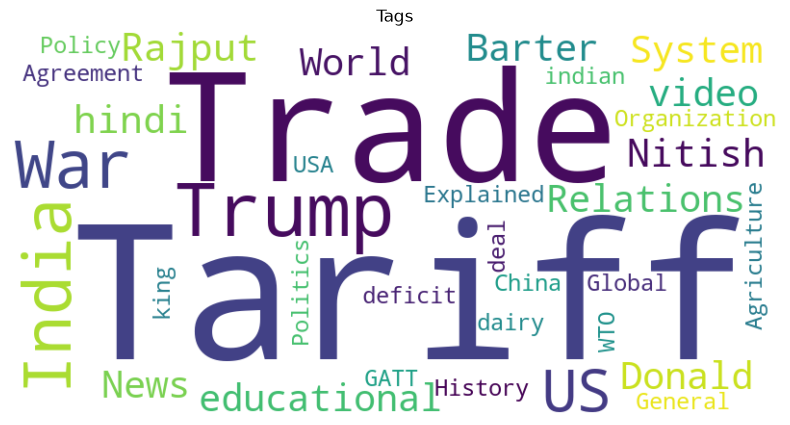

In [278]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Suppose video_info is a list of dicts
tags = []
for vid in variables['video_info']:
    tags.extend(vid.get('tags', []))

# Build word cloud
text = " ".join(tags)
wordcloud = WordCloud(width=800, height=400, background_color="white", colormap="viridis").generate(text)

# Show
plt.figure(figsize=(10,5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Tags")
plt.show()


In [261]:
variables['topics'][0].keys()


dict_keys(['id', 'name', 'confidence', 'size', 'percentage', 'keywords', 'avg_likes', 'avg_replies', 'total_likes', 'total_replies', 'representative_comment', 'top_comments', 'summary', 'category', 'creator_takeaway'])